# Experiment 10: Intelligent Decision Support System
**Application chosen:** Loan Approval Decision Support (bank loan officer assistant)

**Aim:** To develop an intelligent decision-support system using rule-based reasoning, learning from examples, and ethical AI evaluation.

| Exercise | What this notebook does |
|---|---|
| 1. Expert System | Knowledge base + forward-chaining inference engine → APPROVE / REVIEW / REJECT |
| 2. Imitation Learning | Train Decision Tree & Logistic Regression on a human officer's past decisions |
| 3. Explanation Facility | Rule traces, tree rules, per-applicant feature contributions |
| 4. Ethical AI | Group fairness metrics, counterfactual (gender-flip) test, transparency review, mitigation |
| 5. Testing & Comparison | Modify rules / training examples and compare before vs after |

## 0. Setup and synthetic data

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings; warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

rng = np.random.default_rng(42)

### Dataset
No real data is provided, so we simulate loan applicants and a **human loan officer**.
* `merit` = an objective "true creditworthiness" score (no gender involved) → `merit_label` is the fair ground truth.
* The human officer's decisions = merit + small noise **− a hidden penalty for female applicants**. This deliberately injects bias so that Exercise 4 has something to detect (a model that imitates humans also imitates their biases).
* Women's average income is also set slightly lower in the simulation, which creates a *proxy* effect.

In [2]:
N = 1500
gender = rng.choice(["Male", "Female"], N)
age    = rng.integers(21, 66, N)
region = rng.choice(["Urban", "Rural"], N, p=[0.6, 0.4])

income = rng.lognormal(10.9, 0.45, N) * np.where(gender == "Female", 0.92, 1.0)
income = income.clip(15000, 250000).round(-2)
credit_score = rng.normal(660, 80, N).clip(300, 850).round()
debt_ratio   = (rng.beta(2, 5, N) * 0.9 + 0.05).round(3)
employment_years = np.clip((age - 21) * rng.uniform(0.2, 0.9, N), 0, 30).round(1)
loan_amount = (income * rng.uniform(0.1, 0.8, N)).round(-2)

df = pd.DataFrame(dict(age=age, gender=gender, region=region, income=income,
                       credit_score=credit_score, debt_ratio=debt_ratio,
                       employment_years=employment_years, loan_amount=loan_amount))
df["loan_to_income"] = (df.loan_amount / df.income).round(3)

# objective merit score (0..1)
df["merit"] = (0.45 * (df.credit_score - 300) / 550
               + 0.25 * (1 - df.debt_ratio)
               + 0.10 * np.minimum(df.employment_years / 10, 1)
               + 0.20 * (1 - df.loan_to_income))
THRESH = 0.65
df["merit_label"] = (df.merit > THRESH).astype(int)          # fair ground truth

# biased human officer: noise + hidden penalty for women
noise = rng.normal(0, 0.04, N)
bias_penalty = np.where(df.gender == "Female", 0.06, 0.0)
df["human_decision"] = ((df.merit + noise - bias_penalty) > THRESH).astype(int)

print(df.head())
print("\nApproval rate (human):", df.human_decision.mean().round(3))
print(df.groupby("gender")[["human_decision", "merit_label"]].mean().round(3))

   age  gender region    income  credit_score  debt_ratio  employment_years  loan_amount  loan_to_income     merit  merit_label  human_decision
0   44    Male  Rural   87100.0         690.0       0.400               8.2      69200.0           0.794  0.592291            0               0
1   32  Female  Rural   35500.0         813.0       0.337               2.3      15000.0           0.423  0.723877            1               1
2   31  Female  Urban   15000.0         728.0       0.329               5.6       8500.0           0.567  0.660532            1               0
3   35    Male  Urban   24500.0         626.0       0.119              11.4       2800.0           0.114  0.764177            1               1
4   47    Male  Rural  102700.0         725.0       0.605              16.3      75300.0           0.733  0.599877            0               0

Approval rate (human): 0.377
        human_decision  merit_label
gender                             
Female           0.257        0.52

---
## Exercise 1: Expert System (Knowledge Base + Inference Engine)

* **Knowledge base (KB):** IF–THEN rules. *Intermediate rules* turn raw numbers into symbolic facts (e.g. `credit_good`). *Decision rules* combine those facts into a recommendation.
* **Inference engine:** **forward chaining** – start with the applicant's facts, fire rules whose conditions hold, add new facts, repeat until nothing new is derived; then decision rules are checked by **priority** (conflict resolution = first matching rule wins).
* Every fired rule is logged → this is the **explanation trace** used in Exercise 3.
* Thresholds sit in a config dictionary so rules can be modified easily (Exercise 5).

In [3]:
DEFAULT_CONFIG = dict(credit_good=700, credit_poor=600, debt_low=0.35,
                      debt_high=0.50, emp_stable=3, lti_ok=0.40)

class ExpertSystem:
    def __init__(self, cfg=None, name="ES-v1"):
        self.name = name
        self.cfg = {**DEFAULT_CONFIG, **(cfg or {})}
        self._build_kb()

    # ---------------- Knowledge base ----------------
    def _build_kb(self):
        c = self.cfg
        # (rule_id, human-readable text, condition(raw, facts) -> bool, derived fact)
        self.fact_rules = [
            ("R1", f"IF credit_score >= {c['credit_good']} THEN credit_good",
             lambda r, s: r["credit_score"] >= c["credit_good"], "credit_good"),
            ("R2", f"IF {c['credit_poor']} <= credit_score < {c['credit_good']} THEN credit_fair",
             lambda r, s: c["credit_poor"] <= r["credit_score"] < c["credit_good"], "credit_fair"),
            ("R3", f"IF credit_score < {c['credit_poor']} THEN credit_poor",
             lambda r, s: r["credit_score"] < c["credit_poor"], "credit_poor"),
            ("R4", f"IF debt_ratio <= {c['debt_low']} THEN debt_low",
             lambda r, s: r["debt_ratio"] <= c["debt_low"], "debt_low"),
            ("R5", f"IF debt_ratio > {c['debt_high']} THEN debt_high",
             lambda r, s: r["debt_ratio"] > c["debt_high"], "debt_high"),
            ("R6", f"IF employment_years >= {c['emp_stable']} THEN job_stable",
             lambda r, s: r["employment_years"] >= c["emp_stable"], "job_stable"),
            ("R7", f"IF loan_amount/income <= {c['lti_ok']} THEN loan_affordable",
             lambda r, s: r["loan_amount"] / r["income"] <= c["lti_ok"], "loan_affordable"),
        ]
        # Decision rules in PRIORITY order: (id, text, condition(facts), decision, confidence)
        self.decision_rules = [
            ("D1", "IF credit_poor THEN REJECT",
             lambda s: "credit_poor" in s, "REJECT", "high"),
            ("D2", "IF debt_high THEN REJECT",
             lambda s: "debt_high" in s, "REJECT", "high"),
            ("D3", "IF credit_good AND debt_low AND job_stable AND loan_affordable THEN APPROVE",
             lambda s: {"credit_good", "debt_low", "job_stable", "loan_affordable"} <= s, "APPROVE", "high"),
            ("D4", "IF credit_good AND loan_affordable AND NOT debt_high THEN APPROVE",
             lambda s: {"credit_good", "loan_affordable"} <= s and "debt_high" not in s, "APPROVE", "medium"),
            ("D5", "IF credit_fair AND debt_low AND loan_affordable THEN REVIEW (manual)",
             lambda s: {"credit_fair", "debt_low", "loan_affordable"} <= s, "REVIEW", "medium"),
        ]
        self.default = ("D6", "DEFAULT: no approving rule fired THEN REJECT", "REJECT", "low")

    # ---------------- Inference engine (forward chaining) ----------------
    def decide(self, applicant):
        raw = dict(applicant)
        facts, trace, changed = set(), [], True
        while changed:                                  # repeat until no new fact
            changed = False
            for rid, text, cond, fact in self.fact_rules:
                if fact not in facts and cond(raw, facts):
                    facts.add(fact); changed = True
                    trace.append((rid, text))
        for rid, text, cond, decision, conf in self.decision_rules:
            if cond(facts):
                trace.append((rid, text))
                return dict(decision=decision, rule=rid, confidence=conf, facts=facts, trace=trace)
        rid, text, decision, conf = self.default
        trace.append((rid, text))
        return dict(decision=decision, rule=rid, confidence=conf, facts=facts, trace=trace)

    def predict_df(self, data):
        return [self.decide(r)["decision"] for r in data.to_dict("records")]

    def show_kb(self):
        print(f"=== Knowledge base: {self.name} ===")
        for rid, text, *_ in self.fact_rules: print(rid, "|", text)
        for rid, text, *_ in self.decision_rules: print(rid, "|", text)
        print(self.default[0], "|", self.default[1])

es_v1 = ExpertSystem()
es_v1.show_kb()

=== Knowledge base: ES-v1 ===
R1 | IF credit_score >= 700 THEN credit_good
R2 | IF 600 <= credit_score < 700 THEN credit_fair
R3 | IF credit_score < 600 THEN credit_poor
R4 | IF debt_ratio <= 0.35 THEN debt_low
R5 | IF debt_ratio > 0.5 THEN debt_high
R6 | IF employment_years >= 3 THEN job_stable
R7 | IF loan_amount/income <= 0.4 THEN loan_affordable
D1 | IF credit_poor THEN REJECT
D2 | IF debt_high THEN REJECT
D3 | IF credit_good AND debt_low AND job_stable AND loan_affordable THEN APPROVE
D4 | IF credit_good AND loan_affordable AND NOT debt_high THEN APPROVE
D5 | IF credit_fair AND debt_low AND loan_affordable THEN REVIEW (manual)
D6 | DEFAULT: no approving rule fired THEN REJECT


In [4]:
df["es_v1"] = es_v1.predict_df(df)
df["es_v1_bin"] = (df.es_v1 == "APPROVE").astype(int)     # REVIEW treated as "not auto-approved"

print(df.es_v1.value_counts(), "\n")
print("Expert system vs human officer  (accuracy):", round(accuracy_score(df.human_decision, df.es_v1_bin), 3))
print("Expert system vs fair merit label (accuracy):", round(accuracy_score(df.merit_label, df.es_v1_bin), 3))
print("\nRule usage:")
print(pd.Series([es_v1.decide(r)["rule"] for r in df.to_dict("records")]).value_counts())

es_v1
REJECT     1150
REVIEW      183
APPROVE     167
Name: count, dtype: int64 

Expert system vs human officer  (accuracy): 0.71
Expert system vs fair merit label (accuracy): 0.601

Rule usage:
D6    694
D1    322
D5    183
D2    134
D3    111
D4     56
Name: count, dtype: int64


---
## Exercise 2: Imitation Learning
Train models on the **human officer's example decisions** and evaluate how well they imitate them on unseen applicants.
We use a Decision Tree (interpretable rules) and Logistic Regression (interpretable weights). Gender is included as an input **on purpose** – this is the "naive" imitator that will be audited in Exercise 4.

In [5]:
df["gender_female"] = (df.gender == "Female").astype(int)
df["region_urban"]  = (df.region == "Urban").astype(int)

FEATURES      = ["age", "income", "credit_score", "debt_ratio", "employment_years",
                 "loan_amount", "loan_to_income", "gender_female", "region_urban"]
FEATURES_FAIR = [f for f in FEATURES if f != "gender_female"]      # used later

train_idx, test_idx = train_test_split(df.index, test_size=0.3, random_state=42, stratify=df.human_decision)
train, test = df.loc[train_idx].copy(), df.loc[test_idx].copy()
y_train, y_test = train.human_decision, test.human_decision
print("Train:", len(train), "  Test:", len(test))

dt = DecisionTreeClassifier(max_depth=4, random_state=42).fit(train[FEATURES], y_train)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(train[FEATURES], y_train)

test["dt_pred"] = dt.predict(test[FEATURES])
test["lr_pred"] = lr.predict(test[FEATURES])
test["es_pred"] = (pd.Series(es_v1.predict_df(test), index=test.index) == "APPROVE").astype(int)

for name, col in [("Decision Tree", "dt_pred"), ("Logistic Regression", "lr_pred"), ("Expert System (rules)", "es_pred")]:
    print(f"{name:24s} accuracy vs human officer: {accuracy_score(y_test, test[col]):.3f}")

print("\nDecision Tree report:\n", classification_report(y_test, test.dt_pred, target_names=["Reject", "Approve"]))
print("Confusion matrix (rows = human, cols = model):\n", confusion_matrix(y_test, test.dt_pred))

Train: 1050   Test: 450
Decision Tree            accuracy vs human officer: 0.807
Logistic Regression      accuracy vs human officer: 0.880
Expert System (rules)    accuracy vs human officer: 0.733

Decision Tree report:
               precision    recall  f1-score   support

      Reject       0.82      0.89      0.85       280
     Approve       0.78      0.68      0.73       170

    accuracy                           0.81       450
   macro avg       0.80      0.78      0.79       450
weighted avg       0.80      0.81      0.80       450

Confusion matrix (rows = human, cols = model):
 [[248  32]
 [ 55 115]]


---
## Exercise 3: Explanation Facility
Show *why* each system made its recommendation:
* Expert system → exact rules that fired (full trace).
* Decision tree → human-readable IF–THEN rules + feature importance.
* Logistic regression → contribution of every input factor for a given applicant.

In [6]:
def explain_expert(applicant, es=es_v1):
    res = es.decide(applicant)
    print(f"RECOMMENDATION: {res['decision']}   (final rule {res['rule']}, confidence: {res['confidence']})")
    print("Derived facts :", sorted(res["facts"]))
    print("Rules fired   :")
    for rid, text in res["trace"]:
        print(f"   {rid}: {text}")

def explain_logreg(row, top=5):
    x = row[FEATURES].astype(float).values.reshape(1, -1)
    scaler, clf = lr.named_steps["standardscaler"], lr.named_steps["logisticregression"]
    contrib = clf.coef_[0] * scaler.transform(x)[0]
    s = pd.Series(contrib, index=FEATURES).sort_values(key=abs, ascending=False)
    p = lr.predict_proba(x)[0, 1]
    print(f"Logistic Regression: P(approve) = {p:.2f}  → {'APPROVE' if p >= 0.5 else 'REJECT'}")
    print("Top factors (positive pushes toward APPROVE, negative toward REJECT):")
    for f, v in s.head(top).items():
        print(f"   {f:18s} {v:+.2f}   (value = {row[f]})")

samples = test.sample(2, random_state=7)
for i, (_, row) in enumerate(samples.iterrows(), 1):
    print("=" * 70)
    print(f"APPLICANT {i}:", row[["age", "gender", "income", "credit_score", "debt_ratio",
                                  "employment_years", "loan_amount"]].to_dict())
    print("Human officer decided:", "APPROVE" if row.human_decision else "REJECT")
    print("-" * 70); explain_expert(row.to_dict())
    print("-" * 70); explain_logreg(row)

APPLICANT 1: {'age': 36, 'gender': 'Male', 'income': 74600.0, 'credit_score': 723.0, 'debt_ratio': 0.537, 'employment_years': 11.1, 'loan_amount': 56400.0}
Human officer decided: REJECT
----------------------------------------------------------------------
RECOMMENDATION: REJECT   (final rule D2, confidence: high)
Derived facts : ['credit_good', 'debt_high', 'job_stable']
Rules fired   :
   R1: IF credit_score >= 700 THEN credit_good
   R5: IF debt_ratio > 0.5 THEN debt_high
   R6: IF employment_years >= 3 THEN job_stable
   D2: IF debt_high THEN REJECT
----------------------------------------------------------------------
Logistic Regression: P(approve) = 0.07  → REJECT
Top factors (positive pushes toward APPROVE, negative toward REJECT):
   loan_to_income     -2.35   (value = 0.756)
   debt_ratio         -2.13   (value = 0.537)
   credit_score       +1.84   (value = 723.0)
   gender_female      +1.21   (value = 0)
   loan_amount        +0.24   (value = 56400.0)
APPLICANT 2: {'age': 4

=== Decision Tree rules learned from human decisions ===
|--- credit_score <= 685.50
|   |--- loan_to_income <= 0.29
|   |   |--- gender_female <= 0.50
|   |   |   |--- employment_years <= 1.90
|   |   |   |   |--- class: 0
|   |   |   |--- employment_years >  1.90
|   |   |   |   |--- class: 1
|   |   |--- gender_female >  0.50
|   |   |   |--- debt_ratio <= 0.33
|   |   |   |   |--- class: 0
|   |   |   |--- debt_ratio >  0.33
|   |   |   |   |--- class: 0
|   |--- loan_to_income >  0.29
|   |   |--- credit_score <= 625.50
|   |   |   |--- employment_years <= 22.40
|   |   |   |   |--- class: 0
|   |   |   |--- employment_years >  22.40
|   |   |   |   |--- class: 0
|   |   |--- credit_score >  625.50
|   |   |   |--- gender_female <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- gender_female >  0.50
|   |   |   |   |--- class: 0
|--- credit_score >  685.50
|   |--- loan_to_income <= 0.56
|   |   |--- employment_years <= 6.25
|   |   |   |--- gender_female <= 0.50
|   |   |   

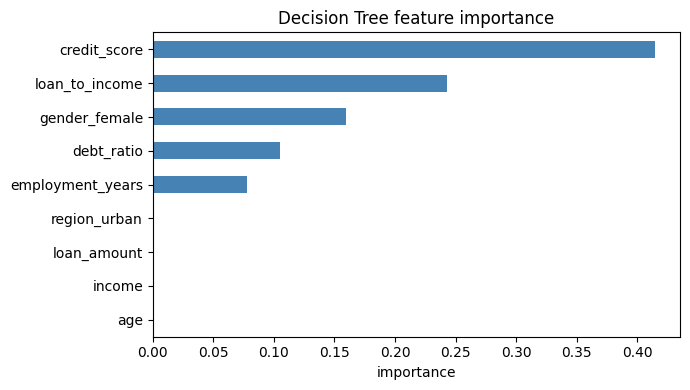

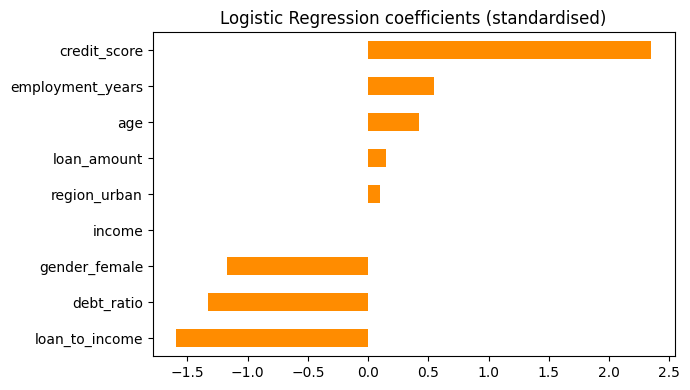

In [7]:
print("=== Decision Tree rules learned from human decisions ===")
print(export_text(dt, feature_names=FEATURES))

imp = pd.Series(dt.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind="barh", figsize=(7, 4), color="steelblue", title="Decision Tree feature importance")
plt.xlabel("importance"); plt.tight_layout(); plt.show()

coefs = pd.Series(lr.named_steps["logisticregression"].coef_[0], index=FEATURES).sort_values()
coefs.plot(kind="barh", figsize=(7, 4), color="darkorange", title="Logistic Regression coefficients (standardised)")
plt.tight_layout(); plt.show()

---
## Exercise 4: Ethical AI – Bias, Fairness and Transparency
**Metrics (protected attribute = gender):**
* **Selection rate** – % approved in each group.
* **Demographic Parity Difference (DPD)** = SR(Male) − SR(Female); ideal ≈ 0.
* **Disparate Impact ratio (DI)** = SR(Female) / SR(Male); the "80 % rule" says DI should be ≥ 0.80.
* **Equal Opportunity difference (EO)** = TPR(Male) − TPR(Female), where TPR is measured on *truly creditworthy* applicants (`merit_label = 1`). Ideal ≈ 0.
* **Counterfactual test** – flip gender only, keep everything else identical; any changed prediction is direct discrimination.

In [8]:
def fairness_report(name, y_pred, group, y_true):
    y_pred, group, y_true = map(np.asarray, (y_pred, group, y_true))
    out = {}
    for g in ["Male", "Female"]:
        m = group == g
        out[f"SelRate_{g}"] = y_pred[m].mean()
        out[f"TPR_{g}"]     = y_pred[m & (y_true == 1)].mean()
    out["DPD (M-F)"]  = out["SelRate_Male"] - out["SelRate_Female"]
    out["DI ratio"]   = out["SelRate_Female"] / out["SelRate_Male"]
    out["EO diff"]    = out["TPR_Male"] - out["TPR_Female"]
    out["Passes 80% rule"] = "YES" if out["DI ratio"] >= 0.8 else "NO"
    return pd.Series(out, name=name)

systems = {"Human officer (training labels)": test.human_decision,
           "Expert system": test.es_pred,
           "Decision tree (with gender)": test.dt_pred,
           "Logistic reg. (with gender)": test.lr_pred}
fair_tbl = pd.DataFrame([fairness_report(n, p, test.gender, test.merit_label) for n, p in systems.items()])
fair_tbl.round(3)

,SelRate_Male,TPR_Male,SelRate_Female,TPR_Female,DPD (M-F),DI ratio,EO diff,Passes 80% rule
Human officer (training labels),0.504,0.894,0.248,0.529,0.257,0.491,0.365,NO
Expert system,0.140,0.308,0.126,0.269,0.014,0.899,0.038,YES
Decision tree (with gender),0.434,0.731,0.216,0.404,0.218,0.498,0.327,NO
Logistic reg. (with gender),0.465,0.952,0.234,0.500,0.231,0.504,0.452,NO


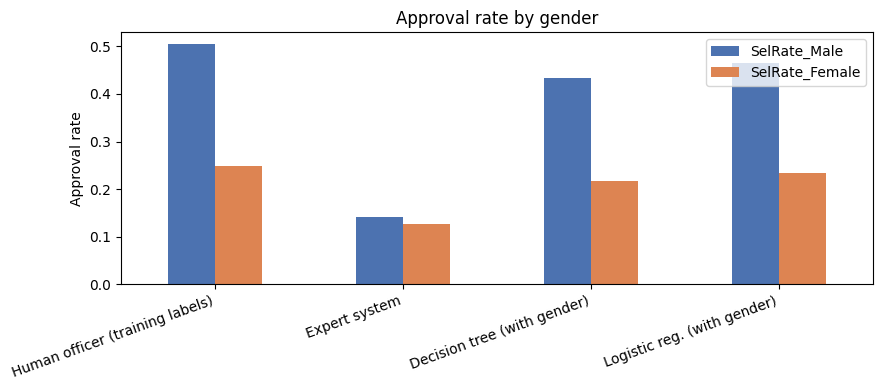

Counterfactual test – % of applicants whose decision changes when ONLY gender is flipped:
   Expert system         :   0.0%  (0 of 450)
   Decision tree         :  22.4%  (101 of 450)
   Logistic regression   :  21.1%  (95 of 450)

Approval rate by REGION and AGE BAND:
        human_decision  es_pred  dt_pred  lr_pred
region                                           
Rural            0.381    0.108    0.301    0.330
Urban            0.376    0.150    0.343    0.365
          human_decision  es_pred  dt_pred  lr_pred
age_band                                           
<30                0.230    0.098    0.279    0.197
30-50              0.403    0.124    0.333    0.339
>50                0.472    0.176    0.359    0.500

Identical profile, gender_female=0: ES=APPROVE, DT=1, LR P(approve)=0.91

Identical profile, gender_female=1: ES=APPROVE, DT=1, LR P(approve)=0.50


In [9]:
# Bar chart of selection rates
ax = fair_tbl[["SelRate_Male", "SelRate_Female"]].plot(kind="bar", figsize=(9, 4), color=["#4c72b0", "#dd8452"])
ax.set_ylabel("Approval rate"); ax.set_title("Approval rate by gender"); plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.show()

# ---- Counterfactual (gender-flip) test ----
flipped = test.copy()
flipped["gender_female"] = 1 - flipped["gender_female"]
flipped["gender"] = np.where(flipped.gender_female == 1, "Female", "Male")
cf = {
    "Expert system":        (pd.Series(es_v1.predict_df(flipped), index=flipped.index) == "APPROVE").astype(int).values != test.es_pred.values,
    "Decision tree":        dt.predict(flipped[FEATURES]) != test.dt_pred.values,
    "Logistic regression":  lr.predict(flipped[FEATURES]) != test.lr_pred.values,
}
print("Counterfactual test – % of applicants whose decision changes when ONLY gender is flipped:")
for k, v in cf.items(): print(f"   {k:22s}: {v.mean()*100:5.1f}%  ({v.sum()} of {len(v)})")

# ---- Other groups / input conditions ----
test["age_band"] = pd.cut(test.age, [0, 30, 50, 100], labels=["<30", "30-50", ">50"])
print("\nApproval rate by REGION and AGE BAND:")
print(test.groupby("region")[["human_decision", "es_pred", "dt_pred", "lr_pred"]].mean().round(3))
print(test.groupby("age_band")[["human_decision", "es_pred", "dt_pred", "lr_pred"]].mean().round(3))

# ---- Same financial profile, different gender (matched pair) ----
base = dict(age=35, income=60000, credit_score=720, debt_ratio=0.30, employment_years=8,
            loan_amount=20000, loan_to_income=20000/60000, region_urban=1)
for g in [0, 1]:
    p = {**base, "gender_female": g}
    prob = lr.predict_proba(pd.DataFrame([p])[FEATURES])[0, 1]
    print(f"\nIdentical profile, gender_female={g}: ES={es_v1.decide(p)['decision']}, "
          f"DT={dt.predict(pd.DataFrame([p])[FEATURES])[0]}, LR P(approve)={prob:.2f}")

In [10]:
# ---- Mitigation: remove gender and re-train; check proxy variables ----
dt_fair = DecisionTreeClassifier(max_depth=4, random_state=42).fit(train[FEATURES_FAIR], y_train)
lr_fair = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(train[FEATURES_FAIR], y_train)
test["dt_fair"] = dt_fair.predict(test[FEATURES_FAIR])
test["lr_fair"] = lr_fair.predict(test[FEATURES_FAIR])

systems2 = {**systems, "Decision tree (gender removed)": test.dt_fair, "Logistic reg. (gender removed)": test.lr_fair}
fair_tbl2 = pd.DataFrame([fairness_report(n, p, test.gender, test.merit_label) for n, p in systems2.items()])
display(fair_tbl2.round(3))

print("\nProxy check – correlation of each feature with gender_female:")
print(df[FEATURES].corr()["gender_female"].drop("gender_female").round(3).sort_values())

,SelRate_Male,TPR_Male,SelRate_Female,TPR_Female,DPD (M-F),DI ratio,EO diff,Passes 80% rule
Human officer (training labels),0.504,0.894,0.248,0.529,0.257,0.491,0.365,NO
Expert system,0.140,0.308,0.126,0.269,0.014,0.899,0.038,YES
Decision tree (with gender),0.434,0.731,0.216,0.404,0.218,0.498,0.327,NO
Logistic reg. (with gender),0.465,0.952,0.234,0.500,0.231,0.504,0.452,NO
Decision tree (gender removed),0.316,0.654,0.306,0.567,0.009,0.970,0.087,YES
Logistic reg. (gender removed),0.355,0.779,0.315,0.673,0.040,0.888,0.106,YES



Proxy check – correlation of each feature with gender_female:
income             -0.079
loan_amount        -0.049
age                -0.026
employment_years   -0.025
debt_ratio         -0.021
region_urban       -0.016
credit_score        0.009
loan_to_income      0.015
Name: gender_female, dtype: float64


### Transparency & fairness evaluation (summary)
| System | Transparency | Fairness finding |
|---|---|---|
| Expert system | **Fully transparent** – every decision has a rule-by-rule trace; no gender input, so it passes the counterfactual test by construction. | Not affected by the human's bias, but rules are hand-written and may encode designer assumptions (e.g. thresholds). Cannot learn from data. |
| Decision tree | Readable rules, but tree structure can change with data. | Learns the hidden gender penalty from the human labels if gender is an input. |
| Logistic regression | Coefficients show direction & size of every factor. | A negative `gender_female` coefficient is direct evidence of learned bias. |
| Gender removed | Same transparency. | Direct discrimination disappears, but **proxy** features (e.g. income) and still-biased labels can keep a gap → remove gender **and** audit/clean the labels. |

**Key lesson:** imitation learning copies the human's biases. Fairness must be measured on outcomes, not assumed.

---
## Exercise 5: Testing and Comparison (before vs after changes)
**(A)** Modify the **rules** (relax thresholds) → compare Expert System v1 vs v2.
**(B)** Modify the **training examples** (replace biased labels by corrected, merit-based labels and drop gender) → compare model before vs after.

In [11]:
# ---------- (A) Modify the rules ----------
es_v2 = ExpertSystem(cfg=dict(credit_good=680, debt_low=0.40, lti_ok=0.45, emp_stable=2), name="ES-v2 (relaxed)")
es_v2.show_kb()

df["es_v2"] = es_v2.predict_df(df)
print("\nDecision counts  v1 vs v2:")
print(pd.DataFrame({"v1": df.es_v1.value_counts(), "v2": df.es_v2.value_counts()}).fillna(0).astype(int))
print("\nTransition table (rows = v1, cols = v2):")
print(pd.crosstab(df.es_v1, df.es_v2))
changed = df[df.es_v1 != df.es_v2]
print(f"\nDecisions changed by rule modification: {len(changed)} of {len(df)} ({len(changed)/len(df)*100:.1f}%)")

df["es_v2_bin"] = (df.es_v2 == "APPROVE").astype(int)
cmp_rules = pd.DataFrame([
    fairness_report("ES v1", df.es_v1_bin, df.gender, df.merit_label),
    fairness_report("ES v2", df.es_v2_bin, df.gender, df.merit_label)])
cmp_rules["Accuracy vs merit"] = [accuracy_score(df.merit_label, df.es_v1_bin), accuracy_score(df.merit_label, df.es_v2_bin)]
cmp_rules["Accuracy vs human"] = [accuracy_score(df.human_decision, df.es_v1_bin), accuracy_score(df.human_decision, df.es_v2_bin)]
display(cmp_rules.round(3))

ex = changed.iloc[0].to_dict()
print("\nExample of a changed decision:")
print("Applicant:", {k: ex[k] for k in ["credit_score", "debt_ratio", "employment_years", "loan_to_income"]})
print("--- v1 ---"); explain_expert(ex, es_v1)
print("--- v2 ---"); explain_expert(ex, es_v2)

=== Knowledge base: ES-v2 (relaxed) ===
R1 | IF credit_score >= 680 THEN credit_good
R2 | IF 600 <= credit_score < 680 THEN credit_fair
R3 | IF credit_score < 600 THEN credit_poor
R4 | IF debt_ratio <= 0.4 THEN debt_low
R5 | IF debt_ratio > 0.5 THEN debt_high
R6 | IF employment_years >= 2 THEN job_stable
R7 | IF loan_amount/income <= 0.45 THEN loan_affordable
D1 | IF credit_poor THEN REJECT
D2 | IF debt_high THEN REJECT
D3 | IF credit_good AND debt_low AND job_stable AND loan_affordable THEN APPROVE
D4 | IF credit_good AND loan_affordable AND NOT debt_high THEN APPROVE
D5 | IF credit_fair AND debt_low AND loan_affordable THEN REVIEW (manual)
D6 | DEFAULT: no approving rule fired THEN REJECT

Decision counts  v1 vs v2:
           v1    v2
APPROVE   167   260
REJECT   1150  1046
REVIEW    183   194

Transition table (rows = v1, cols = v2):
es_v2    APPROVE  REJECT  REVIEW
es_v1                           
APPROVE      167       0       0
REJECT        52    1046      52
REVIEW        41  

,SelRate_Male,TPR_Male,SelRate_Female,TPR_Female,DPD (M-F),DI ratio,EO diff,Passes 80% rule,Accuracy vs merit,Accuracy vs human
ES v1,0.119,0.238,0.104,0.197,0.016,0.869,0.041,YES,0.601,0.710
ES v2,0.171,0.333,0.176,0.313,-0.005,1.030,0.020,YES,0.647,0.744



Example of a changed decision:
Applicant: {'credit_score': 813.0, 'debt_ratio': 0.337, 'employment_years': 2.3, 'loan_to_income': 0.423}
--- v1 ---
RECOMMENDATION: REJECT   (final rule D6, confidence: low)
Derived facts : ['credit_good', 'debt_low']
Rules fired   :
   R1: IF credit_score >= 700 THEN credit_good
   R4: IF debt_ratio <= 0.35 THEN debt_low
   D6: DEFAULT: no approving rule fired THEN REJECT
--- v2 ---
RECOMMENDATION: APPROVE   (final rule D3, confidence: high)
Derived facts : ['credit_good', 'debt_low', 'job_stable', 'loan_affordable']
Rules fired   :
   R1: IF credit_score >= 680 THEN credit_good
   R4: IF debt_ratio <= 0.4 THEN debt_low
   R6: IF employment_years >= 2 THEN job_stable
   R7: IF loan_amount/income <= 0.45 THEN loan_affordable
   D3: IF credit_good AND debt_low AND job_stable AND loan_affordable THEN APPROVE


In [12]:
# ---------- (B) Modify the training examples ----------
# Before: DT trained on biased human labels (with gender).  After: corrected labels (merit-based), gender removed.
dt_before = dt
dt_after  = DecisionTreeClassifier(max_depth=4, random_state=42).fit(train[FEATURES_FAIR], train.merit_label)

test["dt_before"] = dt_before.predict(test[FEATURES])
test["dt_after"]  = dt_after.predict(test[FEATURES_FAIR])

diff = (test.dt_before != test.dt_after)
print(f"Predictions changed after modifying training examples: {diff.sum()} of {len(test)} ({diff.mean()*100:.1f}%)")
print("Direction of change:\n", pd.crosstab(test.dt_before, test.dt_after, rownames=["before"], colnames=["after"]))
print("\nWhich groups were affected? (share of changed predictions)")
print(test[diff].gender.value_counts(normalize=True).round(2))

cmp_ml = pd.DataFrame([
    fairness_report("DT before (biased labels, gender in)", test.dt_before, test.gender, test.merit_label),
    fairness_report("DT after (corrected labels, gender out)", test.dt_after, test.gender, test.merit_label)])
cmp_ml["Accuracy vs human"] = [accuracy_score(test.human_decision, test.dt_before), accuracy_score(test.human_decision, test.dt_after)]
cmp_ml["Accuracy vs merit"] = [accuracy_score(test.merit_label, test.dt_before), accuracy_score(test.merit_label, test.dt_after)]
display(cmp_ml.round(3))

print("\nTree AFTER modification:")
print(export_text(dt_after, feature_names=FEATURES_FAIR))

Predictions changed after modifying training examples: 137 of 450 (30.4%)
Direction of change:
 after     0    1
before          
0       193  110
1        27  120

Which groups were affected? (share of changed predictions)
gender
Female    0.56
Male      0.44
Name: proportion, dtype: float64


,SelRate_Male,TPR_Male,SelRate_Female,TPR_Female,DPD (M-F),DI ratio,EO diff,Passes 80% rule,Accuracy vs human,Accuracy vs merit
"DT before (biased labels, gender in)",0.434,0.731,0.216,0.404,0.218,0.498,0.327,NO,0.807,0.736
"DT after (corrected labels, gender out)",0.487,0.904,0.536,0.885,-0.049,1.101,0.019,YES,0.760,0.853



Tree AFTER modification:
|--- credit_score <= 686.50
|   |--- loan_to_income <= 0.46
|   |   |--- debt_ratio <= 0.32
|   |   |   |--- credit_score <= 593.00
|   |   |   |   |--- class: 0
|   |   |   |--- credit_score >  593.00
|   |   |   |   |--- class: 1
|   |   |--- debt_ratio >  0.32
|   |   |   |--- credit_score <= 605.50
|   |   |   |   |--- class: 0
|   |   |   |--- credit_score >  605.50
|   |   |   |   |--- class: 0
|   |--- loan_to_income >  0.46
|   |   |--- debt_ratio <= 0.27
|   |   |   |--- credit_score <= 625.00
|   |   |   |   |--- class: 0
|   |   |   |--- credit_score >  625.00
|   |   |   |   |--- class: 1
|   |   |--- debt_ratio >  0.27
|   |   |   |--- credit_score <= 652.50
|   |   |   |   |--- class: 0
|   |   |   |--- credit_score >  652.50
|   |   |   |   |--- class: 0
|--- credit_score >  686.50
|   |--- debt_ratio <= 0.53
|   |   |--- age <= 28.50
|   |   |   |--- loan_to_income <= 0.54
|   |   |   |   |--- class: 1
|   |   |   |--- loan_to_income >  0.54
| 

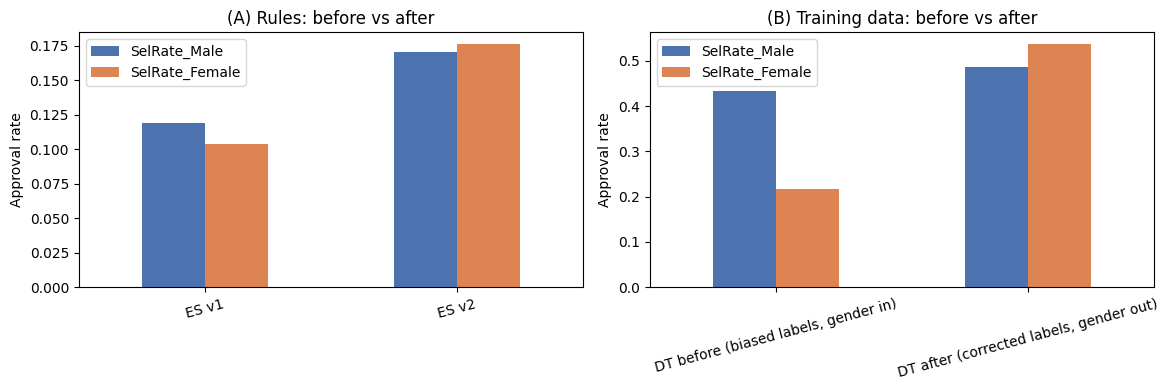

,Approval-rate gap (M-F),Disparate impact ratio
Expert system v1 (test),0.014,0.899
Expert system v2 (full data),-0.005,1.030
Decision tree BEFORE,0.218,0.498
Decision tree AFTER,-0.049,1.101


In [13]:
# ---------- Final side-by-side summary ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cmp_rules[["SelRate_Male", "SelRate_Female"]].plot(kind="bar", ax=axes[0], color=["#4c72b0", "#dd8452"], title="(A) Rules: before vs after")
cmp_ml[["SelRate_Male", "SelRate_Female"]].plot(kind="bar", ax=axes[1], color=["#4c72b0", "#dd8452"], title="(B) Training data: before vs after")
for a in axes: a.set_ylabel("Approval rate"); a.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    "Approval-rate gap (M-F)": [fair_tbl.loc["Expert system", "DPD (M-F)"], cmp_rules.loc["ES v2", "DPD (M-F)"],
                                cmp_ml.iloc[0]["DPD (M-F)"], cmp_ml.iloc[1]["DPD (M-F)"]],
    "Disparate impact ratio":  [fair_tbl.loc["Expert system", "DI ratio"], cmp_rules.loc["ES v2", "DI ratio"],
                                cmp_ml.iloc[0]["DI ratio"], cmp_ml.iloc[1]["DI ratio"]],
}, index=["Expert system v1 (test)", "Expert system v2 (full data)", "Decision tree BEFORE", "Decision tree AFTER"])
summary.round(3)

---
## Conclusion
1. **Expert system:** rule-based reasoning with forward chaining gives consistent, fully explainable loan recommendations, but only as good as the thresholds the designer chose.
2. **Imitation learning:** Decision Tree and Logistic Regression reproduce the human officer's decisions with good accuracy on unseen applicants, and better than the hand-written rules do, because the rules are deliberately conservative (REVIEW cases count as not approved).
3. **Explanation:** rule traces, tree rules and feature contributions make each recommendation auditable.
4. **Ethical AI:** the models trained on human examples absorbed the officer's hidden gender penalty (lower female approval rate, DI ratio and equal-opportunity gap, and decisions flip when only gender is changed). The rule-based system, which never sees gender, did not show direct discrimination.
5. **Testing & comparison:** relaxing the rules increased approvals and changed specific, traceable decisions; correcting the training labels and removing the sensitive attribute removed the gender gap and actually improved agreement with the fair merit label, at the cost of agreeing less with the (biased) human officer.

> Real systems must also consider proxy variables, legal requirements, human oversight for REVIEW/borderline cases, and periodic re-auditing.